In [67]:
import numpy as np
import matplotlib.pyplot as plt

In [68]:
with open("output.txt") as file:
    data = file.read()
data = data.replace(" ", "")# remove whitespaces
data = data.replace(";", ",")

line_list = []#each entry corresponds to the data from one model run

for line in data.splitlines():
    if line.startswith('0'): #only use lines containing the model run data
        line_list.append(line)

    

for i in range(len(line_list)):
    line_list[i] = line_list[i].split(",")#split each line into a list of values
    if line_list[i][-1] == '':#remove empty entries at the end of the list
        line_list[i].pop(-1)

data_array = np.array(line_list, dtype=float)#convert the list of lists into a numpy array

In [69]:
n_timesteps = data_array.shape[0]#number of timesteps in the simulation
nlayers = data_array.shape[1]/5#number of layers in the simulation (each layer has 4 values: id, p, T, theta)
print("Number of timesteps:", n_timesteps, "Number of layers: ", nlayers)

Number of timesteps: 8000 Number of layers:  200.0


In [70]:
def get_data_from_array(layer_id, variable):
    """
    Returns the data for a specific layer and variable from the data_array.
    
    Parameters:
    layer_id (int): The ID of the layer (0-indexed).
    variable (str): The variable to retrieve ('p', 'T', or 'theta').
    
    Returns:
    np.ndarray: The data for the specified layer and variable.
    """

    if variable == 'p':
        return data_array[:, layer_id * 5 + 1]
    elif variable == 'theta':
        return data_array[:, layer_id * 5 + 2]
    elif variable == 'T':
        return data_array[:, layer_id * 5 + 3]
    elif variable == 'z':
        return data_array[:, layer_id * 5 + 4]
    else:
        raise ValueError("Variable must be one of 'p', 'T', 'z' or 'theta'.")

In [71]:
temp_val_list = []
height_val_list = []
nlayers = int(nlayers)
for i in range(nlayers):
   temp_val_list.append(get_data_from_array(i,'T'))
   height_val_list.append(get_data_from_array(i, 'z'))
temp_val_list = np.array(temp_val_list)
height_val_list = np.array(height_val_list)#U really only need these once as the height shouldn't change

#for i in range(nlayers):#plot temperature timeseries for all layers
#    plt.figure(figsize=(10, 6), dpi = 100)
#    plt.plot(range(n_timesteps), temp_val_list[i])
#    plt.xlabel("Timesteps [hrs]")
#    plt.ylabel("Temperature [K]")
#    plt.title(f"Temperature timeseries for Model Layer {i}")
#    plt.grid()
#    plt.show()

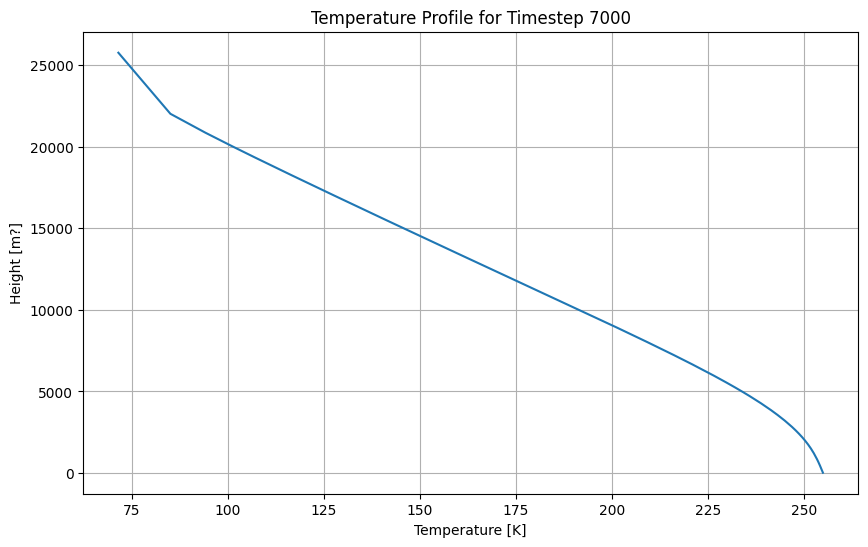

In [75]:
#Create a temperature profile plot. TODO: use geometric height for y-axis. Hand z over as additional value from C code (need to adapt get data method above!)
timestep = 7000#timestep the temp profile should be plotted for

fig, ax = plt.subplots(figsize=(10, 6), dpi=100)
ax.plot(temp_val_list[:, timestep], height_val_list[:, timestep])
#ax.invert_yaxis()
ax.grid()
ax.set_xlabel("Temperature [K]")
ax.set_ylabel("Height [m?]")
ax.set_title(f"Temperature Profile for Timestep {timestep}")
plt.show()